# 7. Basis sets

The basis of numerical atomic orbitals is the approximation that distinguishes the SIESTA method from
plane-wave codes: it is small and efficient, and it must be chosen. This tutorial looks at what a basis is
made of, how the standard sizes compare, and how to control the radii.

**You will learn** to inspect and plot basis functions, to compare basis sizes, and to use `PAO.EnergyShift`
and an explicit `PAO.Basis` block.

Run time: about one minute.

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np

import jax_siesta as js
from jax_siesta.app import build_species, describe_species, parse_pao_basis_block

PSEUDOS = Path("../../examples/pseudos").resolve()
plt.rcParams["figure.dpi"] = 90

## What a basis is made of

`build_species` generates the basis of one species from its pseudopotential. Each basis function is a radial
function times a spherical harmonic. For a DZP basis of silicon:

In [2]:
si_dzp, info = build_species("Si", PSEUDOS / "Si.psml", "DZP", xc="PBE")
print("\n".join(describe_species(si_dzp)))

  Si: Z = 14, valence charge = 4.00, 5 radial functions, 13 orbitals per atom, core correction
      n=3 s  zeta 1   rc =   5.0005 Bohr
      n=3 s  zeta 2   rc =   4.3820 Bohr
      n=3 p  zeta 1   rc =   6.2314 Bohr
      n=3 p  zeta 2   rc =   5.0005 Bohr
      n=3 d  zeta 1   rc =   6.2314 Bohr
      Kleinman-Bylander projectors: 2 s, 2 p, 2 d


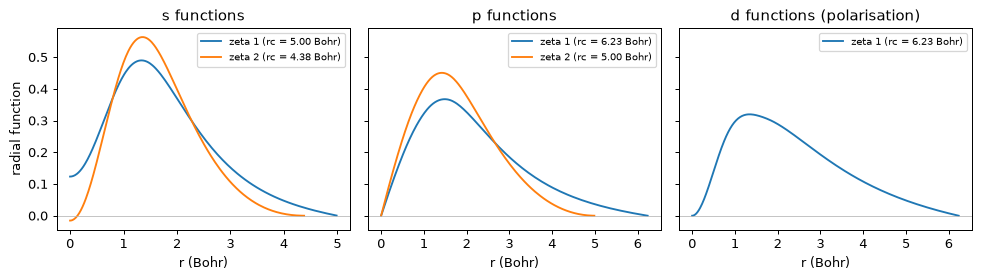

In [3]:
r = np.asarray(si_dzp.pao_r)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for values, ang, zeta, rc in zip(np.asarray(si_dzp.pao_values), si_dzp.pao_l, si_dzp.pao_zeta, si_dzp.pao_rcut):
    axes[ang].plot(r[r <= rc], values[r <= rc], label=f"zeta {zeta} (rc = {rc:.2f} Bohr)")
for ang, ax in enumerate(axes):
    ax.set_title(f"{'spd'[ang]} functions" + (" (polarisation)" if ang == 2 else ""))
    ax.set_xlabel("r (Bohr)")
    ax.legend(fontsize=8)
    ax.axhline(0.0, color="0.7", lw=0.6)
axes[0].set_ylabel("radial function")
fig.tight_layout()

* The **first zeta** of each shell is the orbital of the free pseudo-atom, confined so that it vanishes at a
  cut-off radius.
* The **second zeta** is a more compact function with a shorter cut-off radius, built from the first by
  SIESTA's split-valence construction. Mixing the two lets the orbital contract or expand when the atom
  bonds.
* The **polarisation** function has the next angular momentum (d for silicon) and describes the deformation
  of the valence shell by the field of its neighbours.

## Basis sizes

How do the standard sizes compare for bulk silicon? The calculation of the electronic structure is
variational, so a bigger basis always gives a lower energy.

In [4]:
a = 5.47
cell = a * np.array([[0.0, 0.5, 0.5], [0.5, 0.0, 0.5], [0.5, 0.5, 0.0]])
silicon = js.make_structure(cell, ["Si", "Si"], [[0, 0, 0], [0.25, 0.25, 0.25]], fractional=True)
settings = dict(k_grid=(4, 4, 4), xc_functional="PBE", mesh_cutoff_ry=150.0, use_symmetry=True)

rows = []
for size in ("SZ", "SZP", "DZ", "DZP", "TZP", "TZ2P"):
    calc = js.Calculation.from_structure(silicon, PSEUDOS, basis=size, **settings)
    t0 = time.perf_counter()
    res = calc.run()
    gap = res.band_structure([("Γ", (0, 0, 0)), ("X", (0.5, 0.0, 0.5))], 20).band_gap_ev
    rows.append((size, res.basis.n_orb, res.energy_ev, res.pressure_gpa, gap, time.perf_counter() - t0))

e_best = rows[-1][2]
print(f"{'basis':6s} {'orbitals':>8s} {'E − E(TZ2P) (meV/atom)':>24s} {'P (GPa)':>9s} {'gap (eV)':>9s} {'time (s)':>9s}")
for size, n_orb, energy, pressure, gap, seconds in rows:
    print(f"{size:6s} {n_orb:8d} {(energy - e_best) * 500:24.1f} {pressure:9.2f} {gap:9.3f} {seconds:9.1f}")

basis  orbitals   E − E(TZ2P) (meV/atom)   P (GPa)  gap (eV)  time (s)
SZ            8                    878.6      7.04     1.879      13.4
SZP          18                    474.2      4.63     0.709      14.3
DZ           16                    561.5      3.40     1.464       6.6
DZP          26                     51.7      0.28     0.567       6.9
TZP          34                     43.3      0.46     0.571      10.4
TZ2P         44                      0.0      0.00     0.613      14.4


Reading the table:

* Polarisation functions matter more than a second zeta for the energy of silicon: `SZP` is below `DZ`.
* `DZP` is about 50 meV per atom above the largest basis, with a pressure within 0.3 GPa and a gap within
  0.05 eV of it. Energy *differences* converge faster than these absolute numbers. This is why DZP is the
  default.
* The cost grows quickly with the number of orbitals. (The times include compilation for each new basis.)

## The energy shift

The cut-off radii are set indirectly by `PAO.EnergyShift`: the energy an orbital gains by being confined. A
smaller shift means longer orbitals, a better basis, and more neighbours per atom.

In [5]:
print(f"{'shift (Ry)':>10s} {'rc(3s)':>8s} {'rc(3p)':>8s} {'matrix elements':>16s} {'E (eV)':>12s}")
for shift in (0.04, 0.02, 0.01, 0.005):
    calc = js.Calculation.from_structure(silicon, PSEUDOS, basis="DZP", energy_shift_ry=shift, **settings)
    res = calc.run()
    sp = calc.species["Si"]
    print(f"{shift:10.3f} {sp.pao_rcut[0]:8.3f} {sp.pao_rcut[2]:8.3f} {res.pattern.n_edges:16d} {res.energy_ev:12.4f}")

shift (Ry)   rc(3s)   rc(3p)  matrix elements       E (eV)


     0.040    4.480    5.461            28054    -229.5169


     0.020    5.001    6.231            28054    -229.9094


     0.010    5.342    6.805            49686    -229.9939


     0.005    5.833    7.596            49686    -230.0374


The energy converges from above as the orbitals get longer, while the number of non-zero matrix elements,
and with it the cost, grows.

## The split norm, and why hydrogen is special

`PAO.SplitNorm` sets where the second zeta separates from the first: it is the fraction of the norm of the
first zeta that lies beyond the matching radius. The default, 0.15, gives a second zeta almost as extended
as the first. That suits most elements, but not hydrogen, whose 1s orbital contracts strongly when it bonds.
SIESTA has a separate keyword for it, `PAO.SplitNormH` (here `split_norm_h`), with 0.5 as the recommended
value. The bond length of H₂ shows the effect.

In [6]:
def h2(d, box=7.0):
    c = box / 2.0
    return js.make_structure(np.eye(3) * box, ["H", "H"], [[c - d / 2.0, c, c], [c + d / 2.0, c, c]])


lengths = np.linspace(0.70, 0.82, 7)
for split_h in (0.15, 0.5):
    calc = js.Calculation.from_structure(
        h2(0.75), PSEUDOS, basis="DZP", xc_functional="PBE", mesh_cutoff_ry=250.0, split_norm_h=split_h
    )
    energies = np.array([calc.with_structure(h2(d)).run().energy_ev for d in lengths])
    cubic = np.polyfit(lengths, energies, 3)
    d0 = min(np.roots(np.polyder(cubic)).real, key=lambda x: abs(x - 0.76))
    print(f"split norm {split_h:4.2f}: second-zeta radius {calc.species['H'].pao_rcut[1]:.2f} Bohr   "
          f"bond length {d0:.3f} Ang   energy {np.polyval(cubic, d0):.3f} eV")

split norm 0.15: second-zeta radius 3.76 Bohr   bond length 0.777 Ang   energy -31.305 eV


split norm 0.50: second-zeta radius 2.37 Bohr   bond length 0.748 Ang   energy -31.543 eV


With the default the bond is 0.03 Å too long; with 0.5 it is within 0.002 Å of the converged PBE value
(0.750 Å), and the energy is 0.24 eV lower, which by the variational principle means a better basis. **For
systems with hydrogen, set `PAO.SplitNormH 0.5`.**

## Explicit control: `PAO.Basis`

The `PAO.Basis` block of SIESTA fixes every radius. Here is a DZP basis for silicon with chosen radii and a
soft-confinement potential (`E`) on the s shell. The same block can be put in an input file.

In [7]:
block = """
Si  2
  n=3  0  2  E 50.0 4.0
    6.5  4.5
  n=3  1  2  P 1
    7.5  5.0
"""
spec = parse_pao_basis_block([line.split() for line in block.strip().splitlines()], xc="PBE")["Si"]
custom = js.Calculation.from_structure(silicon, PSEUDOS, basis={"Si": spec}, **settings)
print("\n".join(describe_species(custom.species["Si"])))
print("energy (eV):", round(custom.run().energy_ev, 4))

  Si: Z = 14, valence charge = 4.00, 5 radial functions, 13 orbitals per atom, core correction
      n=3 s  zeta 1   rc =   6.5117 Bohr
      n=3 s  zeta 2   rc =   4.4795 Bohr
      n=3 p  zeta 1   rc =   7.4307 Bohr
      n=3 p  zeta 2   rc =   5.0005 Bohr
      n=3 d  zeta 1   rc =   7.4307 Bohr
      Kleinman-Bylander projectors: 2 s, 2 p, 2 d


energy (eV): -230.0531


Choosing these numbers by hand is tedious. jsiesta includes an optimiser that minimises the *basis enthalpy*
(the energy plus a pressure times the volume occupied by the orbitals) over the radii and confinement
parameters for a set of training structures, and writes the result as a `PAO.Basis` block:
`jax_siesta.species.optimize_basis_enthalpy` (see the *Species* section of the API reference).

## A caution when comparing with SIESTA

jsiesta generates its bases with its own implementation of SIESTA's recipe. The radii and energies are close
to those of SIESTA but not identical, so total energies of the two codes differ by tens of meV when each
generates its own basis. To use exactly the basis of a SIESTA run, give jsiesta the `.ion.xml` files that
SIESTA writes (`User.Basis T`).

## Exercises

1. Plot the radial functions of the oxygen DZP basis (`O.psml`). Why are its radii so much shorter than those
   of silicon?
2. For the water molecule of tutorial 5, compare the O-H bond force at the starting geometry for `SZ`, `DZ`,
   `DZP` and `TZP`. Which basis property matters most for this molecule?
3. Change the soft-confinement parameters of the block above (`E 50.0 4.0`) to `E 10.0 2.0` and to no
   confinement. How does the shape of the first s function change near its cut-off radius, and what happens to
   the energy?
4. Relax the water molecule of tutorial 5 with `split_norm_h=0.5`. How do the bond length and the angle
   change?
5. Use `energy_shift_ry=0.001`. The radii become very long. What happens to the number of matrix elements and
   to the time? Is the energy gain worth it?